In [1]:
import warnings
import os 
from pathlib import Path
from natsort import natsort_keygen

import pandas as pd
from pathlib import Path
import anndata as ad 
import numpy as np 
from dotenv import dotenv_values

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

warnings.simplefilter(action='ignore', category=FutureWarning)

In [72]:
# Setting up filepaths from config
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

OUTDIR = DATADIR / "publication" / "Supplemental"
os.makedirs(OUTDIR, exist_ok=True)

SC_IN_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_control.h5ad'
OBS_EXT_FP = DATADIR / "9_objects" / "singlecell" / 'hypomap3d_singlecell_all_obs_extended.csv'

L2_INHERITANCE_FP = DATADIR / "10_analyses" / "clustering_comparison" / "inheritance_status_l2.csv"
L3_INHERITANCE_FP = DATADIR / "10_analyses" / "clustering_comparison" / "inheritance_status_l3.csv"

In [3]:

l1_color_map = {
    'Gl1-1 Glut': "#8c564b",
    'Gb1-2 GABA': "#aa40fc",
    'NN1-4 Astro-Epen': "#17becf",
    'NN1-1 OPC-Oligo': "#ffbb78",
    'NN1-2 Immune': "#aec7e8",
    'NN1-3 Vascular': "#98df8a" 
}


In [4]:
adata = ad.read_h5ad(SC_IN_FP, backed="r")

In [ ]:
# Get additional data for ABC mapping

obs = adata.obs.loc[:, ["CellID"] + [c for c in adata.obs.columns if "descr" in c] + [c for c in adata.obs.columns if "abc_like" in c]] 
obs_ext = pd.read_csv(OBS_EXT_FP, low_memory=False)
obs = obs.merge(obs_ext, on="CellID", how="left")

In [5]:
labelmat = adata.obs.loc[~adata.obs.L1_ID.str.contains("NN"), [f"L{i}_descr" for i in range(1,6)]].drop_duplicates()
l2_to_l1 = labelmat.set_index("L2_descr").to_dict()["L1_descr"]
labelmat.head(2)

,L1_descr,L2_descr,L3_descr,L4_descr,L5_descr
SC1-01_SAMN18754353_AAACCCACAACCAGAG,Gl1-1 Glut,Gl2-35 VMH Nr5a1.Acvr1c,Gl3-113 VMH Cobll1,Gl4-290 VMH Cobll1.Vgll2,Gl5-390 VMH Cobll1.Vgll2
SC1-01_SAMN18754353_AAACCCAGTCATCTAG,Gl1-1 Glut,Gl2-33 VMH Fezf1,Gl3-107 VMH Npffr1,Gl4-274 VMH Npffr1.Arhgap36,Gl5-371 VMH Npffr1.Arhgap36.Htr1b


# Preparing data and prototyping parts of the combined cluster tree plots

## Dendrogram 

### Let's build the linkage

In [6]:
subclass_labelmat = labelmat.loc[:, [f"L{i}_descr" for i in range(1,3)]]

In [7]:
def build_custom_linkage(df, level_cols):
    """
    Build a custom linkage matrix Z from a DataFrame using specified hierarchical columns.
    Supports 2 levels of hierarchy.

    Parameters:
        df: pd.DataFrame
        level_cols (list of str): List of column names defining the hierarchy from top to bottom.

    Returns:
        tuple:
            Z (np.ndarray): linkage matrix for dendrogram.
            idx_to_label (dict): mapping from leaf index to bottom-level cluster label.
    """
    assert 2 <= len(level_cols), "Function supports 2 levels of hierarchy"
    
    # Drop duplicates and sort
    df = df[level_cols].drop_duplicates().astype(str)

    key = natsort_keygen()
    df = df.sort_values(
        by=level_cols,
        key=lambda col: col.map(key)
    )

    # sort Gl before Gb or NN
    df = pd.concat([
        df.loc[df[level_cols[0]].str.contains("Gl")],
        df.loc[df[level_cols[0]].str.contains("Gb")],
        df.loc[df[level_cols[0]].str.contains("NN")]
    ], axis=0
    )

    bottom_col = level_cols[-1]
    bottom_clusters = df[bottom_col].unique()
    n_leaves = len(bottom_clusters)

    cluster_sizes = {}
    Z = []
    current_idx = 0
    merge_map = {}

    # Map bottom level clusters to leaf indices
    bottom_to_idx = {name: i for i, name in enumerate(bottom_clusters)}
    idx_to_label = {i: name for i, name in enumerate(bottom_clusters)}
    cluster_sizes = {i: 1 for i in range(n_leaves)}
    current_idx = n_leaves

    # Recursive merging from bottom-up
    for level in reversed(range(1, len(level_cols))):  # Start from second last to top
        parent_col = level_cols[level - 1]
        child_col = level_cols[level]

        merge_map_level = {}
        for parent, group in df.groupby(parent_col):
            child_clusters = group[child_col].unique()
            leaves = [
                merge_map.get(child, bottom_to_idx.get(child))
                for child in child_clusters
            ]

            # Merge all clusters under this parent
            while len(leaves) > 1:
                a = leaves.pop()
                b = leaves.pop()
                size_a = cluster_sizes[a]
                size_b = cluster_sizes[b]
                new_size = size_a + size_b
                Z.append([a, b, 0.2 + 0.1 * level, new_size])  # Distance increases with hierarchy
                cluster_sizes[current_idx] = new_size
                leaves.append(current_idx)
                current_idx += 1

            merge_map_level[parent] = leaves[0]  # Store representative for parent cluster
        merge_map = merge_map_level

    # Final root merge if needed
    final_clusters = list(merge_map.values())
    while len(final_clusters) > 1:
        a = final_clusters.pop()
        b = final_clusters.pop()
        size_a = cluster_sizes[a]
        size_b = cluster_sizes[b]
        new_size = size_a + size_b
        Z.append([a, b, 1.0, new_size])
        cluster_sizes[current_idx] = new_size
        final_clusters.append(current_idx)
        current_idx += 1

    Z = np.array(Z)
    assert Z.shape[0] + 1 == n_leaves, f"Linkage matrix Z has incorrect shape: merges={Z.shape[0]}, leaves={n_leaves}"

    return Z, idx_to_label


In [8]:
Z_subclass, idx_to_l2 = build_custom_linkage(subclass_labelmat, [f"L{i}_descr" for i in range(1,3)])
n_leaves_subclass = subclass_labelmat.L2_descr.nunique()

### Let's get a color map

In [9]:
def propagate_colors_to_deepest_level(df, level_cols, source_level_idx, cluster_color_map, default_color="#A0A0A0"):
    """
    Propagate colors from a specified source level to the deepest level in a hierarchy.

    Parameters:
        df (pd.DataFrame): DataFrame with hierarchical cluster levels as columns.
        level_cols (list of str): Ordered list of columns from top to bottom levels.
        source_level_idx (int): Index in level_cols of the source level (e.g., 0 for top).
        cluster_color_map (dict): Mapping from source level cluster names to colors.
        default_color (str): Default color to use if no mapping is found.

    Returns:
        dict: Mapping from deepest level cluster names to propagated colors.
    """
    assert 2 <= len(level_cols), "Supports 2 hierarchy levels"
    assert 0 <= source_level_idx < len(level_cols), "Invalid source level index"

    # Keep only relevant columns for mapping
    source_col = level_cols[source_level_idx]
    target_col = level_cols[-1]  # deepest level
    df_clean = df[[source_col, target_col]].drop_duplicates().astype(str)

    # Build mapping: deepest level → source level
    deep_to_source = dict(zip(df_clean[target_col], df_clean[source_col]))

    # Propagate color from source level to deepest
    deep_to_color = {
        deep: cluster_color_map.get(source, default_color)
        for deep, source in deep_to_source.items()
    }

    return deep_to_color


In [10]:
l2_to_color = propagate_colors_to_deepest_level(
    labelmat,
    level_cols=["L1_descr", "L2_descr"],
    source_level_idx=0, # propagate from 0 to last index
    cluster_color_map=l1_color_map
)


### Let's plot

In [11]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

def plot_colored_dendrogram(Z, idx_to_label, leaf_label_to_color, linewidth=1.5, default_color="#000000", **kwargs):
    """
    Plots a dendrogram with colored branches based on leaf label to color mapping.

    Parameters:
        Z (np.ndarray): Linkage matrix.
        idx_to_label (dict): Mapping from leaf index to cluster label.
        leaf_label_to_color (dict): Mapping from cluster label to color.
        linewidth (float): Width of the dendrogram lines.
        default_color (str): Color to use when multiple colors are found under a branch.
        kwargs: Additional keyword arguments passed to scipy dendrogram.
    
    Returns:
        dict: The dendrogram object returned by scipy.cluster.hierarchy.dendrogram.
    """

    # Step 1: Build leaf index to color map
    leaf_colors = {
        i: leaf_label_to_color.get(idx_to_label[i], default_color)
        for i in idx_to_label
    }

    # Step 2: Helper to trace leaves under a node
    def trace_leaves(node):
        if node < len(idx_to_label):  # It's a leaf
            return {node}
        else:
            left = int(Z[node - len(idx_to_label), 0])
            right = int(Z[node - len(idx_to_label), 1])
            return trace_leaves(left) | trace_leaves(right)

    # Step 3: Determine color for each internal node
    link_colors = {}
    for i in range(Z.shape[0]):
        a, b = int(Z[i, 0]), int(Z[i, 1])
        leaves = trace_leaves(a) | trace_leaves(b)
        colors = {leaf_colors[leaf] for leaf in leaves}
        link_colors[i + len(idx_to_label)] = (
            colors.pop() if len(colors) == 1 else default_color
        )

    # Step 4: Plot with link color function
    with plt.rc_context({'lines.linewidth': linewidth}):
        dendro = dendrogram(
            Z,
            link_color_func=lambda k: link_colors.get(k, default_color),
            labels=[idx_to_label[i] for i in range(len(idx_to_label))],
            leaf_rotation=90,
            **kwargs
        )

    return dendro


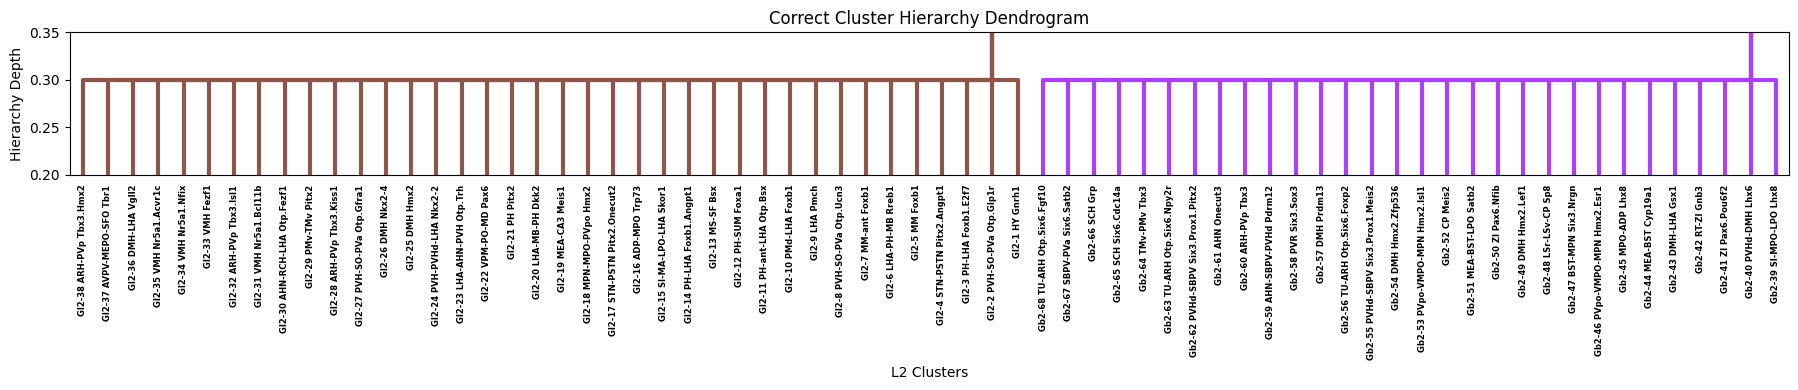

<Figure size 640x480 with 0 Axes>

In [12]:
plt.figure(figsize=(18, 4))
dendro_subclass = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3)

plt.title("Correct Cluster Hierarchy Dendrogram")
plt.xlabel("L2 Clusters")
plt.ylabel("Hierarchy Depth")
plt.xticks(fontweight='bold')
plt.tight_layout()
plt.ylim(0.2, 0.35)


# === Get label positions from x-axis tick labels ===# After plotting dendrogram
ax = plt.gca()
tick_labels = [tick.get_text() for tick in ax.get_xticklabels()]
tick_positions = ax.get_xticks()

label_to_x = {
    label: xpos for label, xpos in zip(tick_labels, tick_positions)
}

# plot parts above the leaves
plt.vlines(x=label_to_x["Gb2-40 PVHd-DMH Lhx6"], 
        ymin = 0.3, ymax=1,
        color=l2_to_color["Gb2-40 PVHd-DMH Lhx6"], linestyle='-', linewidth=3)

plt.vlines(x=label_to_x["Gl2-2 PVH-SO-PVa Otp.Glp1r"], 
        ymin = 0.3, ymax=1,
        color=l2_to_color["Gl2-2 PVH-SO-PVa Otp.Glp1r"], linestyle='-', linewidth=3)

#plt.gca().invert_xaxis()

plt.show()
sns.despine()


In [ ]:
leaf_labels_subclass = tick_labels[::-1] #revert the order to match the plot above

## Matching to ABC

In [76]:

allen_col = "subclass_id_label_propagated"


abc_contrib_subclass = (
    obs.loc[:, ["L2_descr", allen_col]]
    .value_counts()
    .reset_index(name="proportion")
)

# Step 1: Pivot counts data
df_counts_abc = abc_contrib_subclass.pivot(index="L2_descr", columns=allen_col, values="proportion").fillna(0)

# Step 2: Sort values within each row and extract top1, top2, and rest
sorted_dfs = []
for idx, row in df_counts_abc.iterrows():
    sorted_row = row.sort_values(ascending=False)
    top1 = sorted_row.iloc[0:1]
    top2 = sorted_row.iloc[1:2]
    rest = sorted_row.iloc[2:].sum()

    temp = pd.Series({
        "top1_" + top1.index[0]: top1.iloc[0],
        "top2_" + top2.index[0]: top2.iloc[0],
        "rest": rest
    }, name=idx)
    sorted_dfs.append(temp)

df_ranked = pd.DataFrame(sorted_dfs).fillna(0)

# Step 3: Normalize to percentage
df_ranked = df_ranked.div(df_ranked.sum(axis=1), axis=0) * 100

# Step 4: Reorder rows if needed
df_ranked = df_ranked.loc[leaf_labels_subclass, :]

# Step 5: Reorder columns so top1 is at bottom of stack
top1_col = [col for col in df_ranked.columns if col.startswith("top1_")]
top2_col = [col for col in df_ranked.columns if col.startswith("top2_")]
rest_col = [col for col in df_ranked.columns if col == "rest"]

ordered_cols = top1_col + top2_col + rest_col
df_ranked = df_ranked[ordered_cols]

# Step 6: Define fixed colors
color_map = {
    'top1': '#1f77b4',   # Blue
    'top2': '#ff7f0e',   # Orange
    'rest': 'black'
}

plot_colors = []
legend_labels = []

for col in ordered_cols:
    if col.startswith("top1_"):
        plot_colors.append(color_map["top1"])
        legend_labels.append("Top 1 Match")
    elif col.startswith("top2_"):
        plot_colors.append(color_map["top2"])
        legend_labels.append("Top 2 Match")
    else:
        plot_colors.append(color_map["rest"])
        legend_labels.append("Rest")

# Create label → color map for unique legend entries
from collections import OrderedDict
unique_labels = OrderedDict()
for label, color in zip(legend_labels, plot_colors):
    if label not in unique_labels:
        unique_labels[label] = color


In [79]:
# Reset index to turn cluster names into a column
df_match_long = df_ranked.reset_index().melt(id_vars='index', var_name='match_type_raw', value_name='proportion')

# Step 2: Map raw match_type to clean match labels
def map_match_type(colname):
    if colname.startswith("top1_"):
        return "Top 1 Match"
    elif colname.startswith("top2_"):
        return "Top 2 Match"
    else:
        return "Rest"

df_match_long["match_type"] = df_match_long["match_type_raw"].apply(map_match_type)


In [80]:
df_match_long = df_match_long.loc[df_match_long.proportion != 0, ["index", "proportion", "match_type"]]
df_match_long.columns = ["L2_descr", "proportion", "match_type"]

In [81]:
df_match_plot = df_match_long.pivot_table(
    index='L2_descr',
    columns='match_type',
    values='proportion',
    fill_value=0
)

# Ensure correct order
df_match_plot = df_match_plot.loc[leaf_labels_subclass, ["Top 1 Match", "Top 2 Match", "Rest"]]

In [82]:
df_match_plot.head()

match_type,Top 1 Match,Top 2 Match,Rest
L2_descr,,,
Gb2-39 SI-MPO-LPO Lhx8,86.432231,3.249807,10.317962
Gb2-40 PVHd-DMH Lhx6,96.491946,1.337701,2.170352
Gb2-41 ZI Pax6.Pou6f2,79.058116,7.442663,13.499221
Gb2-42 RT-ZI Gnb3,98.669623,0.823567,0.506810
Gb2-43 DMH-LHA Gsx1,92.131431,6.448027,1.420542


## Subclass inheritance

In [42]:
# get ABC to descr mapper 

abc_to_descr_l2 = adata.obs[["L2_abc_like", "L2_descr"]].drop_duplicates().set_index("L2_abc_like").to_dict()["L2_descr"]
abc_to_descr_l3 = adata.obs[["L3_abc_like", "L3_descr"]].drop_duplicates().set_index("L3_abc_like").to_dict()["L3_descr"]

abc_to_desc_mapper = abc_to_descr_l2 | abc_to_descr_l3


In [35]:
l2_n = pd.read_csv(L2_INHERITANCE_FP)

In [43]:
l2_n.source_label = l2_n.source_label.map(abc_to_desc_mapper)

In [44]:
l2_n.head(2)

,source_label,most_probable_match,most_probable_match_counts_relative,is_inherited,hm3d_stem,abc_stem,num_valid_abc_match_occurrences,is_deduplicated,inheritance_status
0,Gb2-39 SI-MPO-LPO Lhx8,085 SI-MPO-LPO Lhx8 Gaba,0.864322,True,SI-MPO-LPO Lhx8 GABA,SI-MPO-LPO Lhx8 GABA,1.0,False,inherited
1,Gb2-40 PVHd-DMH Lhx6,103 PVHd-DMH Lhx6 Gaba,0.964919,True,PVHd-DMH Lhx6 GABA,PVHd-DMH Lhx6 GABA,1.0,False,inherited


In [45]:
# Example hex colors for each inheritance_status category
inheritance_status_colors = {
    "new cluster": "#221f40",  
    "inherited": "#c4c4a5",
    "inherited and deduplicated": "#d39542"    
}

# Make sure clusters appear in the order of leaf_labels_subclass
l2_n = l2_n.set_index("source_label").reindex(leaf_labels_subclass).reset_index()


In [47]:


# Get unique categories in the same order as keys (or define your own order)
status_categories = list(inheritance_status_colors.keys())

# Map each inheritance_status to an integer index (needed for heatmap input)
status_to_num = {status: i for i, status in enumerate(status_categories)}

# Convert inheritance_status to numeric codes
numeric_status = l2_n["inheritance_status"].map(status_to_num)

# Create heatmap data: 1-row with numeric codes as columns
df_status = pd.DataFrame([numeric_status.values], columns=l2_n["source_label"])

# Create ListedColormap from your hex color list (in same order as categories)
cmap_inheritance_status = ListedColormap([inheritance_status_colors[status] for status in status_categories])


/tmp/ipykernel_42832/145771110.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


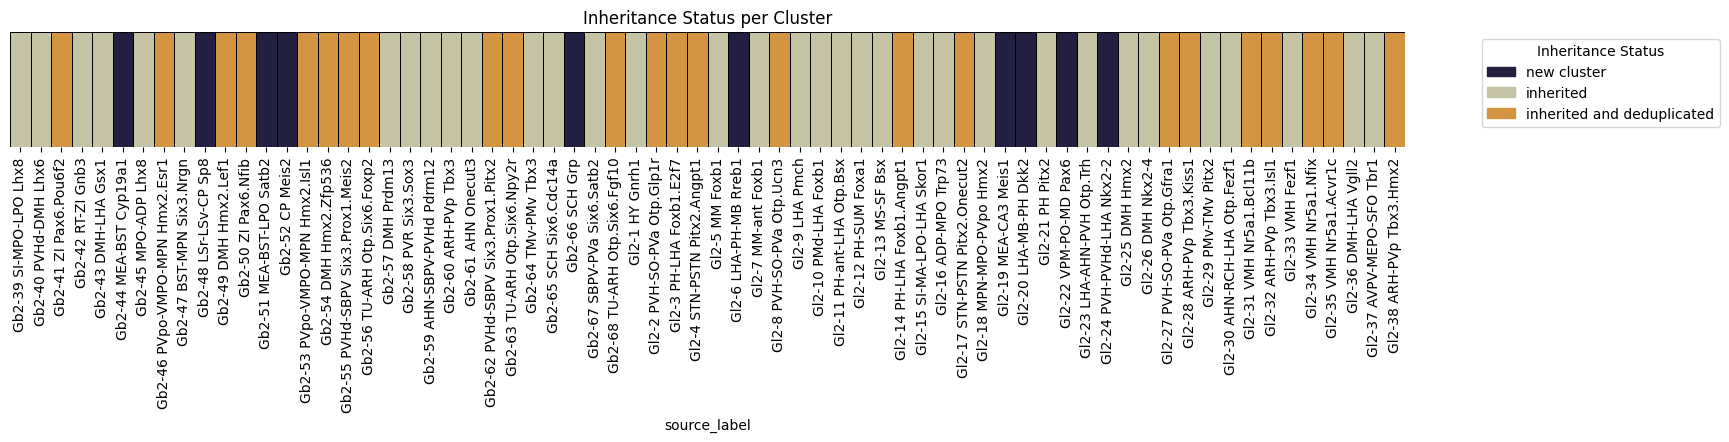

In [50]:

# Plot heatmap
plt.figure(figsize=(18, 1.5))
ax = sns.heatmap(
    df_status,
    cmap=cmap_inheritance_status,
    cbar=False,
    linewidths=0.5,
    linecolor='black',
    xticklabels=True,
    yticklabels=False
)

plt.xticks(rotation=90)
plt.title("Inheritance Status per Cluster")
plt.tight_layout()

# Create legend manually using your hex colors
legend_handles = [Patch(color=inheritance_status_colors[status], label=status) for status in status_categories]
plt.legend(handles=legend_handles, bbox_to_anchor=(1.05, 1), loc='upper left', title="Inheritance Status")

plt.show()


## Num Supertypes

In [52]:
num_super = labelmat.loc[
    ~labelmat["L2_descr"].str.contains("NN"),
    ["L2_descr", "L3_descr"]
].astype(str).groupby("L2_descr")["L3_descr"].nunique().loc[leaf_labels_subclass]

num_super

L2_descr
Gb2-39 SI-MPO-LPO Lhx8       5
Gb2-40 PVHd-DMH Lhx6         4
Gb2-41 ZI Pax6.Pou6f2        6
Gb2-42 RT-ZI Gnb3            4
Gb2-43 DMH-LHA Gsx1          5
                            ..
Gl2-34 VMH Nr5a1.Nfix        3
Gl2-35 VMH Nr5a1.Acvr1c      5
Gl2-36 DMH-LHA Vgll2         3
Gl2-37 AVPV-MEPO-SFO Tbr1    4
Gl2-38 ARH-PVp Tbx3.Hmx2     1
Name: L3_descr, Length: 68, dtype: int64

In [53]:
heatmap_data_num_super = pd.DataFrame([num_super.loc[leaf_labels_subclass].values], 
                            index=["Num supertypes"], 
                            columns=leaf_labels_subclass)


<Axes: >

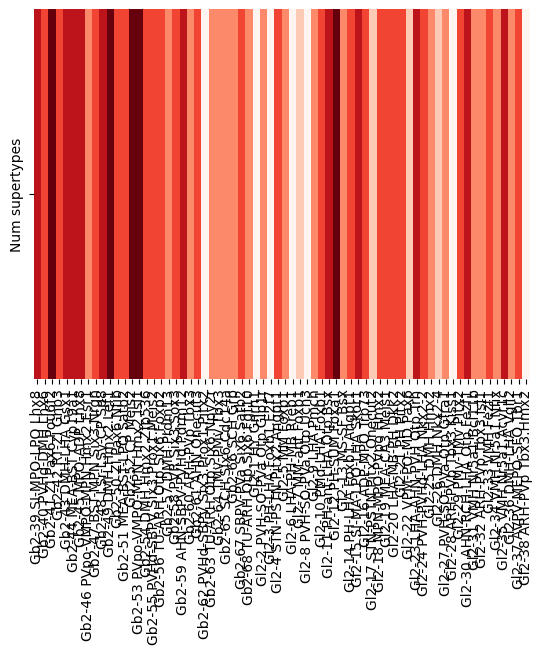

In [54]:

# Plot heatmap
sns.heatmap(
    heatmap_data_num_super, 
    #ax=ax_heatmap,
    cbar_kws={'label': 'Num supertypes', 'shrink': 0.1}, cbar=False,
    cmap="Reds",  yticklabels=True, xticklabels=True,
    #xticklabels=False  # hide ylabels to reduce clutter (since dendro shows labels)
)

## Supertype inheritance

In [60]:
joined_n = pd.read_csv(L3_INHERITANCE_FP)

In [61]:
joined_n.source_label_subclass = joined_n.source_label_subclass.map(abc_to_desc_mapper)

In [66]:
joined_n.mapping_category = joined_n.mapping_category.replace({"new (violates hierarchy)": "new"})

In [67]:
joined_n.head(2)

,hm3d_stem_subclass,source_label_supertype,most_probable_match_supertype,most_probable_match_counts_relative_supertype,hm3d_stem_supertype,abc_stem_supertype,abc_stem_subclass,source_label_subclass,most_probable_match_subclass,most_probable_match_counts_relative_subclass,is_inherited_subclass,abc_stem_subclass_l2,num_valid_abc_match_occurrences_subclass,is_deduplicated_subclass,inheritance_status_subclass,mapping_category
0,SI-MPO-LPO Lhx8 GABA,Gb3-124 SI-MPO-LPO Lhx8 GABA_2,0397 SI-MPO-LPO Lhx8 Gaba_2,0.938826,SI-MPO-LPO Lhx8 GABA_2,SI-MPO-LPO Lhx8 GABA_2,SI-MPO-LPO Lhx8 GABA,Gb2-39 SI-MPO-LPO Lhx8,085 SI-MPO-LPO Lhx8 Gaba,0.864322,True,SI-MPO-LPO Lhx8 GABA,1.0,False,inherited,1:1
1,SI-MPO-LPO Lhx8 GABA,Gb3-125 SI-MPO-LPO Lhx8 GABA_7,0396 SI-MPO-LPO Lhx8 Gaba_1,0.277648,SI-MPO-LPO Lhx8 GABA_7,SI-MPO-LPO Lhx8 GABA_1,SI-MPO-LPO Lhx8 GABA,Gb2-39 SI-MPO-LPO Lhx8,085 SI-MPO-LPO Lhx8 Gaba,0.864322,True,SI-MPO-LPO Lhx8 GABA,1.0,False,inherited,new


In [69]:
supertype_match_categorical = (
    joined_n.loc[:, ["source_label_subclass", "mapping_category"]]
    .value_counts()
    .reset_index(name="proportion")
)
# Pivot the data to get proportions per donor for each leiden cluster
df_supertype_match_categorical = supertype_match_categorical.pivot(index="source_label_subclass", columns="mapping_category", values="proportion")

# Normalize each cluster to make it percentage (i.e. row sum = 1)
df_supertype_match_categorical = df_supertype_match_categorical.div(df_supertype_match_categorical.sum(axis=1), axis=0) * 100

# Reorder clusters to match dendrogram
df_supertype_match_categorical = df_supertype_match_categorical.loc[leaf_labels_subclass,:]
# Generate a color palette with as many unique colors as needed

# Map authors to their assigned color
color_map_supertype_match = {
    "many:1": "#d39542",
    "1:1": "#c4c4a5",
    "new": "#221f40"
    }


/tmp/ipykernel_42832/1552206256.py:13: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


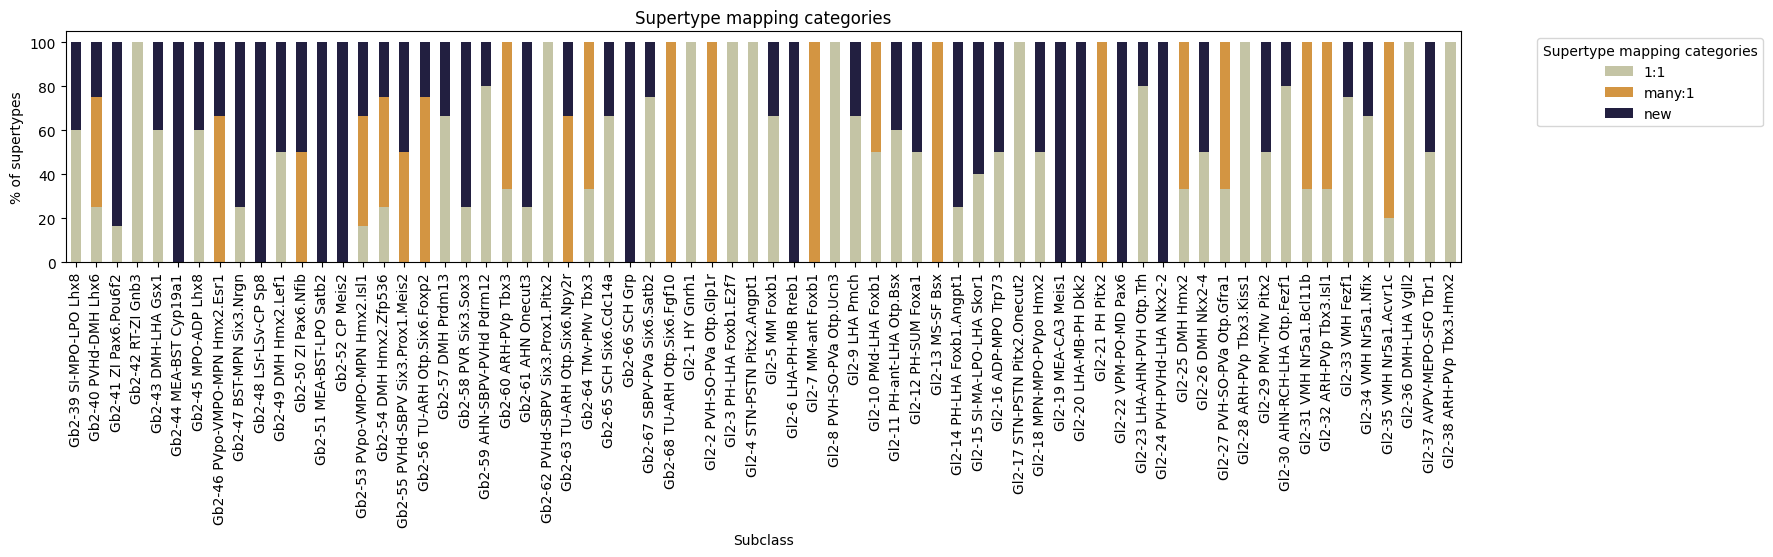

In [70]:

# Plot
ax = df_supertype_match_categorical.plot(
    kind="bar",
    stacked=True,
    figsize=(18, 3),
   color=[color_map_supertype_match[col] for col in df_supertype_match_categorical.columns]
)

plt.xlabel("Subclass")
plt.ylabel("% of supertypes")
plt.title("Supertype mapping categories")
plt.legend(title="Supertype mapping categories", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Combining the above

## Vertical

In [87]:
from matplotlib.colors import LinearSegmentedColormap

# Define a custom black-to-light-blue colormap
black_to_blue = LinearSegmentedColormap.from_list(
    "black_to_lightblue",
    ["black", "#ADD8E6"],  # Black to Light Blue (hex: #ADD8E6)
    N=256
)

leaf_labels_subclass = leaf_labels_subclass[::-1]

/tmp/ipykernel_42832/3278201224.py:230: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


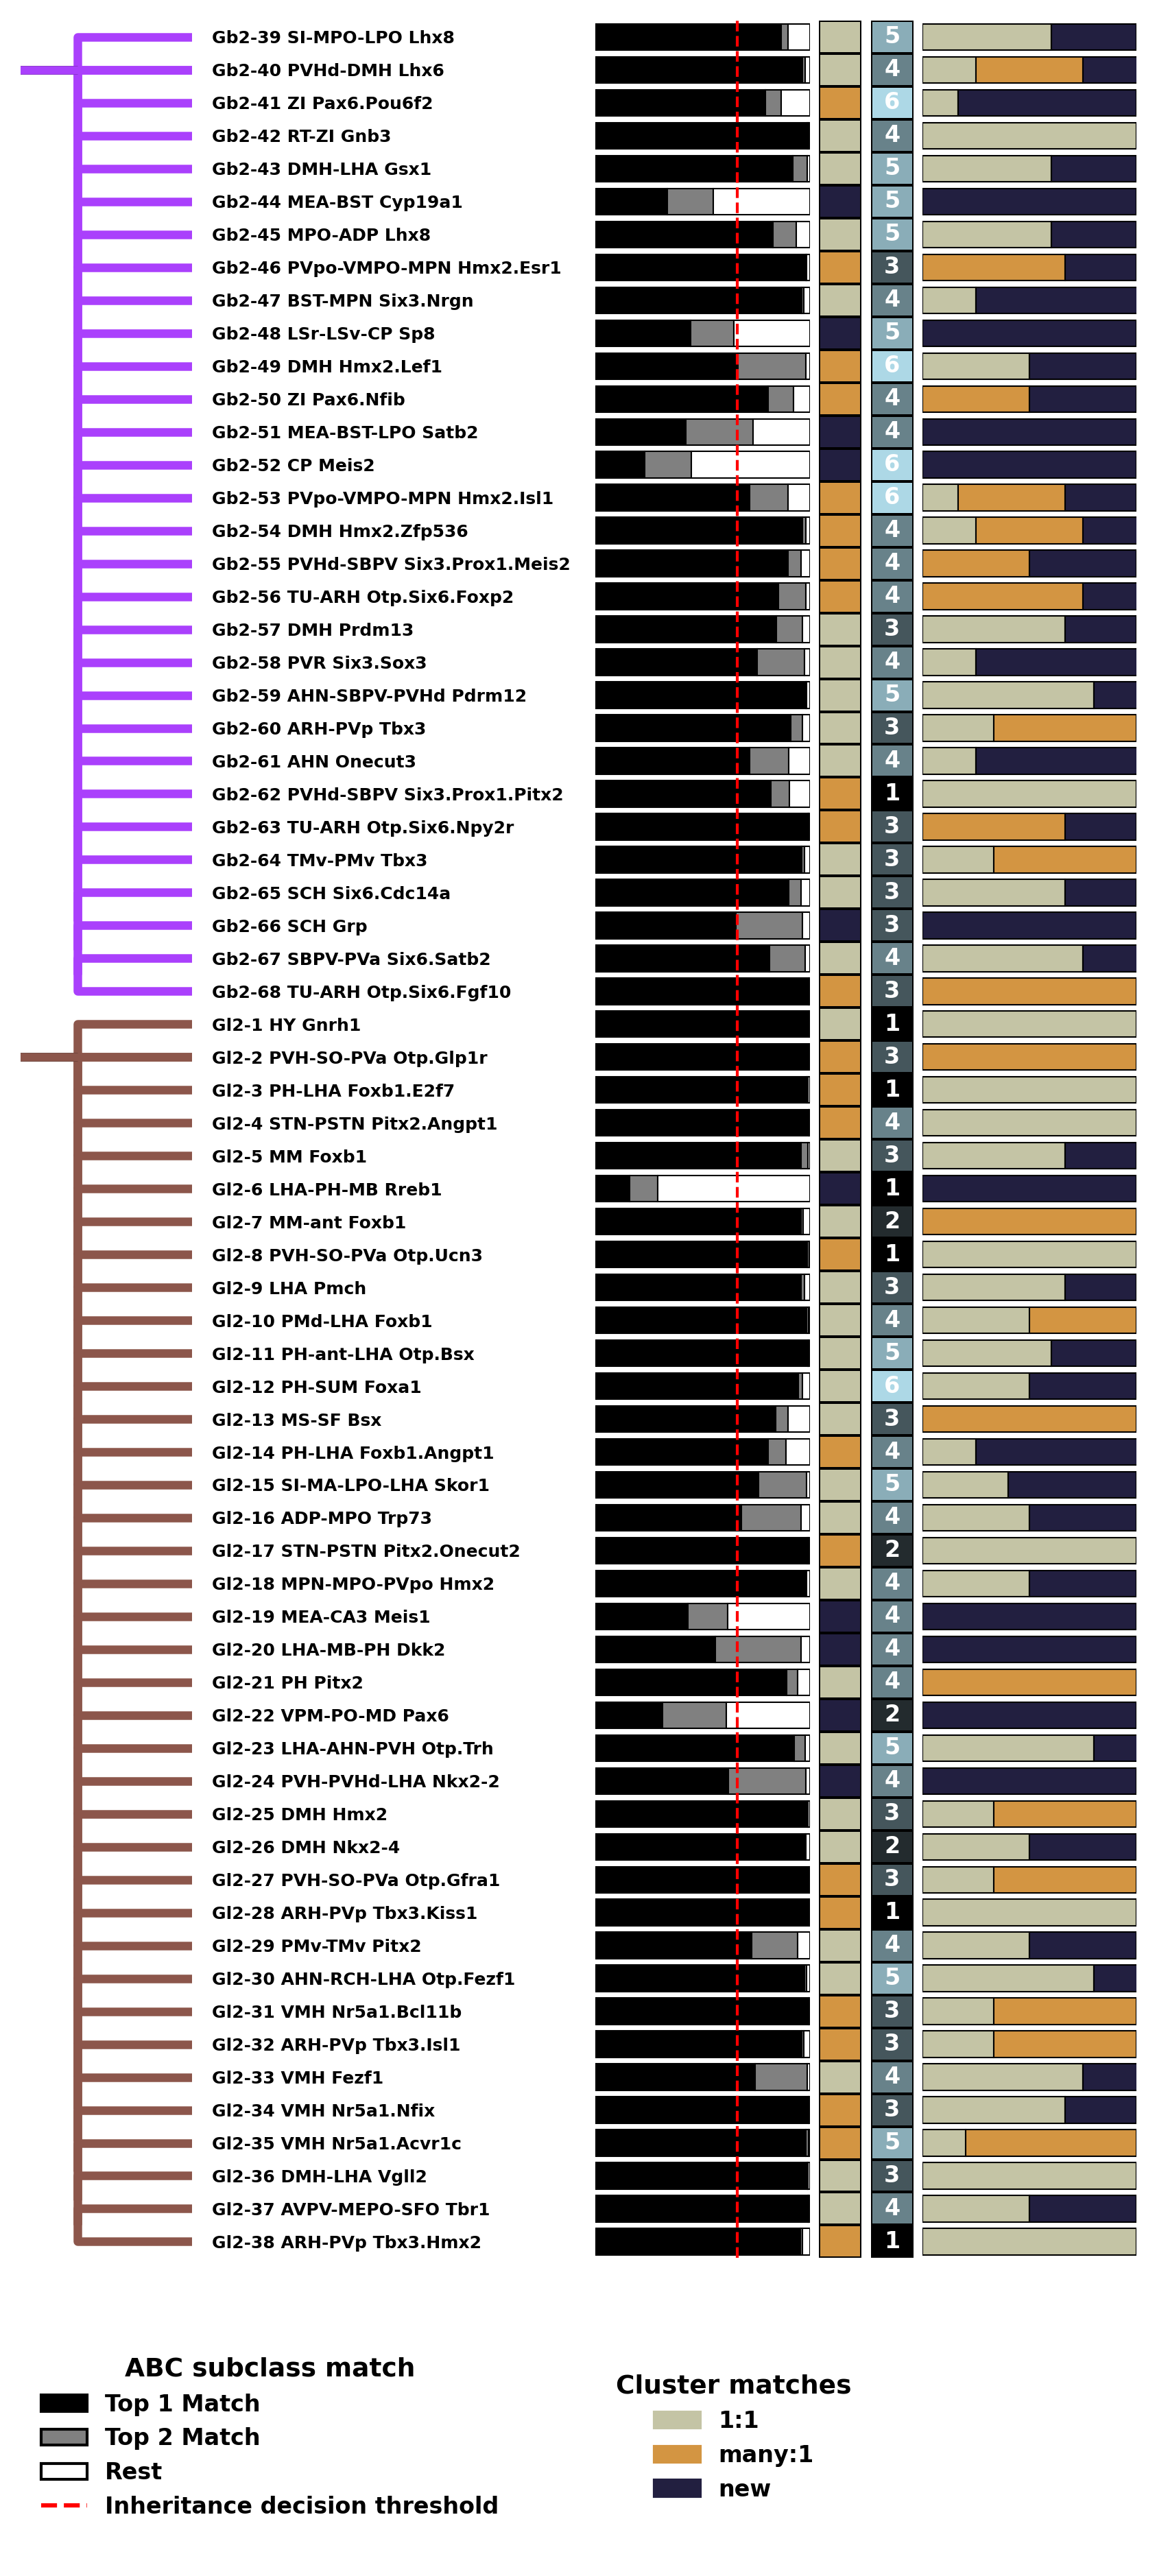

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D


match_color_map = {
    "Top 1 Match": "black",  
    "Top 2 Match": "grey",  
    "Rest": "white"
}


# ===================== Bar Drawing Function =====================
def draw_manual_stacked_bars(ax, df, color_map, cluster_order, category_order=None, bar_height=0.8, annotate=False):
    y_positions = list(range(len(cluster_order)))
    left = np.zeros(len(cluster_order))
    all_categories = category_order if category_order else list(color_map.keys())

    for cat in all_categories:
        if cat not in df.columns:
            df[cat] = 0

    df = df[all_categories].loc[cluster_order].fillna(0)
    handles = []

    for cat in all_categories:
        values = df[cat].values
        bars = ax.barh(
            y_positions, values,
            left=left,
            color=color_map[cat],
            edgecolor='black',
            linewidth=0.5,
            height=bar_height,
            label=cat
        )

        if annotate:
            for yi, xi, w in zip(y_positions, left, values):
                if w > 5:
                    ax.text(
                        xi + w / 2, yi,
                        f"{cat}",
                        va='center', ha='center',
                        fontsize=8,
                        rotation=0,
                        weight='bold',
                        color='black'
                    )

        left += values
        handles.append(Patch(color=color_map[cat], label=cat))

    ax.set_ylim(-0.5, len(cluster_order) - 0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax, left=True, bottom=True)

    return handles


# ==== CONFIG ====
fig = plt.figure(figsize=(7, 16), dpi=300)

leaf_labels = leaf_labels_subclass  # Ensure this is precomputed
y = list(range(len(leaf_labels)))   # Swapped from x -> y for horizontal layout

gs = gridspec.GridSpec(
    nrows=2, ncols=6,
    width_ratios=[0.4, 0.9, 0.5, 0.1, 0.1, 0.5],
    height_ratios=[0.95, 0.1],
    hspace=0.05, wspace=0.05
)

# ===================== 1. Dendrogram =====================
ax_dendro = fig.add_subplot(gs[0, 0])
dendro = plot_colored_dendrogram(Z_subclass, idx_to_l2, l2_to_color, linewidth=3, ax=ax_dendro, orientation='left')
ax_dendro.set_yticklabels(leaf_labels, fontweight='bold', rotation=0)
ax_dendro.set_xlim(0.35, 0.2)
sns.despine(ax=ax_dendro, left=True, bottom=True)
ax_dendro.set_xticks([])
ax_dendro.set_ylabel("")
ax_dendro.set_xlabel("")

tick_labels = [tick.get_text() for tick in ax_dendro.get_yticklabels()]
tick_positions = ax_dendro.get_yticks()
label_to_y = dict(zip(tick_labels, tick_positions))

manual_labels = ["Gb2-40 PVHd-DMH Lhx6", "Gl2-2 PVH-SO-PVa Otp.Glp1r"]

for label in manual_labels:
    if label in label_to_y:
        ypos = label_to_y[label]
        ax_dendro.axhline(y=ypos, color=l2_to_color[label], linestyle='-', linewidth=3)
        
#ax_dendro.set_yticks([])

# ===================== New Stacked Barplot =====================
ax_new_stacked_bar = fig.add_subplot(gs[0, 2])

# Plot stacked bars
handles_new_bar = draw_manual_stacked_bars(
    ax_new_stacked_bar,
    df_match_plot,
    match_color_map,
    cluster_order=leaf_labels_subclass,
    category_order=["Top 1 Match", "Top 2 Match", "Rest"]
)

ax_new_stacked_bar.axvline(
    x=66, 
    color='red', 
    linestyle='--', 
    linewidth=1
)
# ===================== Legend for Horizontal Stacked Barplot =====================
legend_handles = [
    Patch(facecolor=color, edgecolor='black', label=label)
    for label, color in match_color_map.items()
]

threshold_line = Line2D(
    [0], [0],
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Inheritance decision threshold'
)

legend_handles.append(threshold_line)

ax_newbar_leg = fig.add_subplot(gs[1, 0])
ax_newbar_leg.axis("off")
ax_newbar_leg.legend(
    handles=legend_handles,
    title="ABC subclass match",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)

# Final formatting
for leg_ax in [ax_newbar_leg]:
    legend = leg_ax.get_legend()
    if legend:
        legend.get_title().set_fontweight('bold')
        for text in legend.get_texts():
            text.set_fontweight('bold')
# ===================== 2. Subclass inheritance Heatmap =====================

ax_inherit = fig.add_subplot(gs[0, 3])
subclass_inherit_heatmap = sns.heatmap(
    df_status[leaf_labels[::-1]].T,
    cmap=cmap_inheritance_status,
    cbar=False,
    xticklabels=False,
    yticklabels=False,
    linewidth=0.5,
    linecolor='black',
    ax=ax_inherit
)

ax_inherit.set_xticklabels(ax_inherit.get_xticklabels(), fontweight='bold', rotation=90)
ax_inherit.set_yticks([])
ax_inherit.set_xticks([])
ax_inherit.set_xlabel("")
ax_inherit.set_ylabel("")
sns.despine(ax=ax_inherit, left=True, bottom=True)


# ===================== 3. Number of Subclusters Heatmap =====================
ax_num_subclusters = fig.add_subplot(gs[0, 4])
heat_data = heatmap_data_num_super[leaf_labels[::-1]].T  # Transposed

sns.heatmap(
    heat_data,
    cmap=black_to_blue,
    cbar=False,
    xticklabels=False,
    yticklabels=True,
    linewidths=0.5,
    linecolor='black',
    ax=ax_num_subclusters,
    annot=True,
    fmt="d",
    annot_kws={"fontsize": 8, "weight": "bold", "color": "white", "va": "center", "ha": "center"}
)
ax_num_subclusters.set_xticks([])
ax_num_subclusters.set_yticks([])
ax_num_subclusters.set_ylabel("")
sns.despine(ax=ax_num_subclusters, left=True, bottom=True)


# ===================== 4. Supertype matches =====================

ax_supermatch = fig.add_subplot(gs[0, 5])
handles_supertype = draw_manual_stacked_bars(
    ax_supermatch,
    df_supertype_match_categorical,
    color_map_supertype_match,
    leaf_labels,
    category_order=list(df_supertype_match_categorical.columns)
)


ax_supermatch_leg = fig.add_subplot(gs[1, 2])
ax_supermatch_leg.axis("off")
ax_supermatch_leg.legend(
    handles=handles_supertype,
    title="Cluster matches",
    loc="center left",
    frameon=False,
    fontsize=8,
    title_fontsize=9
)
#ax_donor.set_xlabel("")

# ===================== Final Formatting =====================
for leg_ax in [ax_supermatch_leg]:
    legend = leg_ax.get_legend()
    if legend:
        legend.get_title().set_fontweight('bold')
        for text in legend.get_texts():
            text.set_fontweight('bold')

plt.tight_layout()
plt.savefig(OUTDIR / "inheritance_subclass_tree_vertical.pdf", dpi=300, bbox_inches="tight")
plt.show()
